# Analysis 2: Transmission × Body Type Interaction Analysis
**Jira User Story:** `CDS-76` — Advanced Analysis (Acceptance Criterion 2)  
**Business Question:** Does the listing-price difference between Automatic and Manual vehicles vary across body types?

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

SCRIPTS_DIR = Path("scripts").resolve()
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from common import load_dataset, OUTPUT_FIG_DIR
from transmission_body_analysis import run_transmission_body_analysis

df = load_dataset()
res2 = run_transmission_body_analysis(df)
print(f"Total rows: {res2['total_rows']:,} | Major body types retained: {res2['major_body_types_rows']:,} | Excluded: {res2['excluded_rows']:,}")
display(pd.DataFrame(res2["coverage_table"]))

Total rows: 15,229 | Major body types retained: 9,817 | Excluded: 5,412


,real_body_type,Manual,Automatic,Total,Median_Price,Mean_Price,Included_In_Main_Analysis,Status_Reason
0,Unknown,4428,889,5317,490000.0,6.493511e+05,False,Excluded: Unknown/missing body type label
1,Hatchback,3240,361,3601,435000.0,4.580089e+05,True,Included (major body type with both transmissi...
2,Sedan,1791,1048,2839,625000.0,9.268573e+05,True,Included (major body type with both transmissi...
3,SUV,2120,699,2819,880000.0,1.120392e+06,True,Included (major body type with both transmissi...
4,MUV,474,84,558,1077500.0,1.180260e+06,True,Included (major body type with both transmissi...
5,"Crossover, SUV",0,54,54,2125000.0,2.064352e+06,False,Excluded: Only one transmission type observed ...
6,MPV,24,0,24,1070000.0,1.093375e+06,False,Excluded: Only one transmission type observed ...
7,"Sports, Convertible",0,6,6,3712000.0,4.479000e+06,False,Excluded: Only one transmission type observed ...
8,Pick-up,6,0,6,1225000.0,1.223333e+06,False,Excluded: Only one transmission type observed ...
9,Coupe,0,4,4,11300000.0,1.682500e+07,False,Excluded: Only one transmission type observed ...


### Category Coverage & Documented Exclusions
- **Retained Major Body Types (`n = 9,817`, 64.5%):** `Hatchback` (3,601), `Sedan` (2,839), `SUV` (2,819), and `MUV` (558) are the only known body types containing both Manual and Automatic listings (`n >= 84` per cell).
- **Documented Exclusions (`n = 5,412`, 35.5%):**
  - `Unknown` (`n = 5,317`): missing/unlabeled body type.
  - Single-transmission / sparse categories (`Crossover, SUV` 54 Auto / 0 Manual; `MPV` 24 Manual / 0 Auto; `Pick-up` 6 Manual; `Sports, Convertible` 6 Auto; `Coupe` 4 Auto; `Sports` 1 Auto): within-body-type comparison is undefined.

In [2]:
prem_df = pd.DataFrame(res2["premium_table"])
display(prem_df.style.format({
    "manual_median_price": "₹{:,.0f}",
    "automatic_median_price": "₹{:,.0f}",
    "manual_mean_price": "₹{:,.0f}",
    "automatic_mean_price": "₹{:,.0f}",
    "median_diff_inr": "₹{:,.0f}",
    "median_pct_premium": "+{:.2f}%",
}))

reg2 = res2["regression"]
print(f"\nHC3 OLS on log(selling_price): n={reg2['n_obs']:,}, R²={reg2['r2']:.4f}, Adj R²={reg2['adj_r2']:.4f}")
print("Joint Wald F-test for C(transmission_type)*C(real_body_type):", reg2["joint_interaction_f_test"])
display(pd.DataFrame(reg2["adjusted_auto_premium_by_body"]))

,real_body_type,manual_n,automatic_n,total_n,manual_median_price,automatic_median_price,manual_mean_price,automatic_mean_price,median_diff_inr,median_pct_premium
0,Hatchback,3240,361,3601,"₹425,000","₹550,000","₹439,819","₹621,260","₹125,000",+29.41%
1,Sedan,1791,1048,2839,"₹525,000","₹1,125,000","₹556,417","₹1,559,929","₹600,000",+114.29%
2,SUV,2120,699,2819,"₹800,000","₹1,450,000","₹841,282","₹1,966,908","₹650,000",+81.25%
3,MUV,474,84,558,"₹950,000","₹1,800,000","₹1,059,962","₹1,859,083","₹850,000",+89.47%



HC3 OLS on log(selling_price): n=9,817, R²=0.9183, Adj R²=0.9177
Joint Wald F-test for C(transmission_type)*C(real_body_type): {'f_stat': 2.861241739027296, 'df_num': 3, 'df_denom': 9740, 'p_value': 0.03542283442676592}


,real_body_type,log_effect,hc3_se,p_value,adj_pct_premium,adj_pct_ci95_low,adj_pct_ci95_high
0,Hatchback,0.129745,0.009463,8.749197e-43,13.853792,11.761598,15.985153
1,Sedan,0.155273,0.011046,6.966613e-45,16.797705,14.296265,19.353891
2,SUV,0.138432,0.012546,2.615596e-28,14.847158,12.057583,17.706176
3,MUV,0.091849,0.018948,1.251344e-06,9.619908,5.623507,13.767518


### Unadjusted vs. Confounder-Adjusted Interaction Results
- **Raw Median Premiums Look Huge:** Unadjusted Automatic premiums span **`+29.4%` in Hatchbacks** (`₹4.25L -> ₹5.50L`), **`+114.3%` in Sedans** (`₹5.25L -> ₹11.25L`), **`+81.25%` in SUVs** (`₹8.00L -> ₹14.50L`), and **`+89.5%` in MUVs** (`₹9.50L -> ₹18.00L`).
- **Confounding Revealed by HC3 Regression (`R² = 0.9183`):** Controlling for `vehicle_age`, `km_driven`, `engine`, `seller_type`, and `model_grouped` shrinks the Automatic premium to a much tighter band: **Sedan `+16.8%` (95% CI: `14.3%–19.4%`)**, **SUV `+14.8%` (`12.1%–17.7%`)**, **Hatchback `+13.9%` (`11.8%–16.0%`)**, and **MUV `+9.6%` (`5.6%–13.8%`)**.
- **Joint Interaction Test:** Statistically significant ($F(3, 9740) = 2.86, p = 0.0354$), though individual pairwise interaction differences relative to Hatchback are moderate (`±3–4` percentage points). Most of the raw `+81%–114%` gap reflects luxury/higher-trim model mix rather than the gearbox alone.

--- transmission_body_price_comparison.png ---


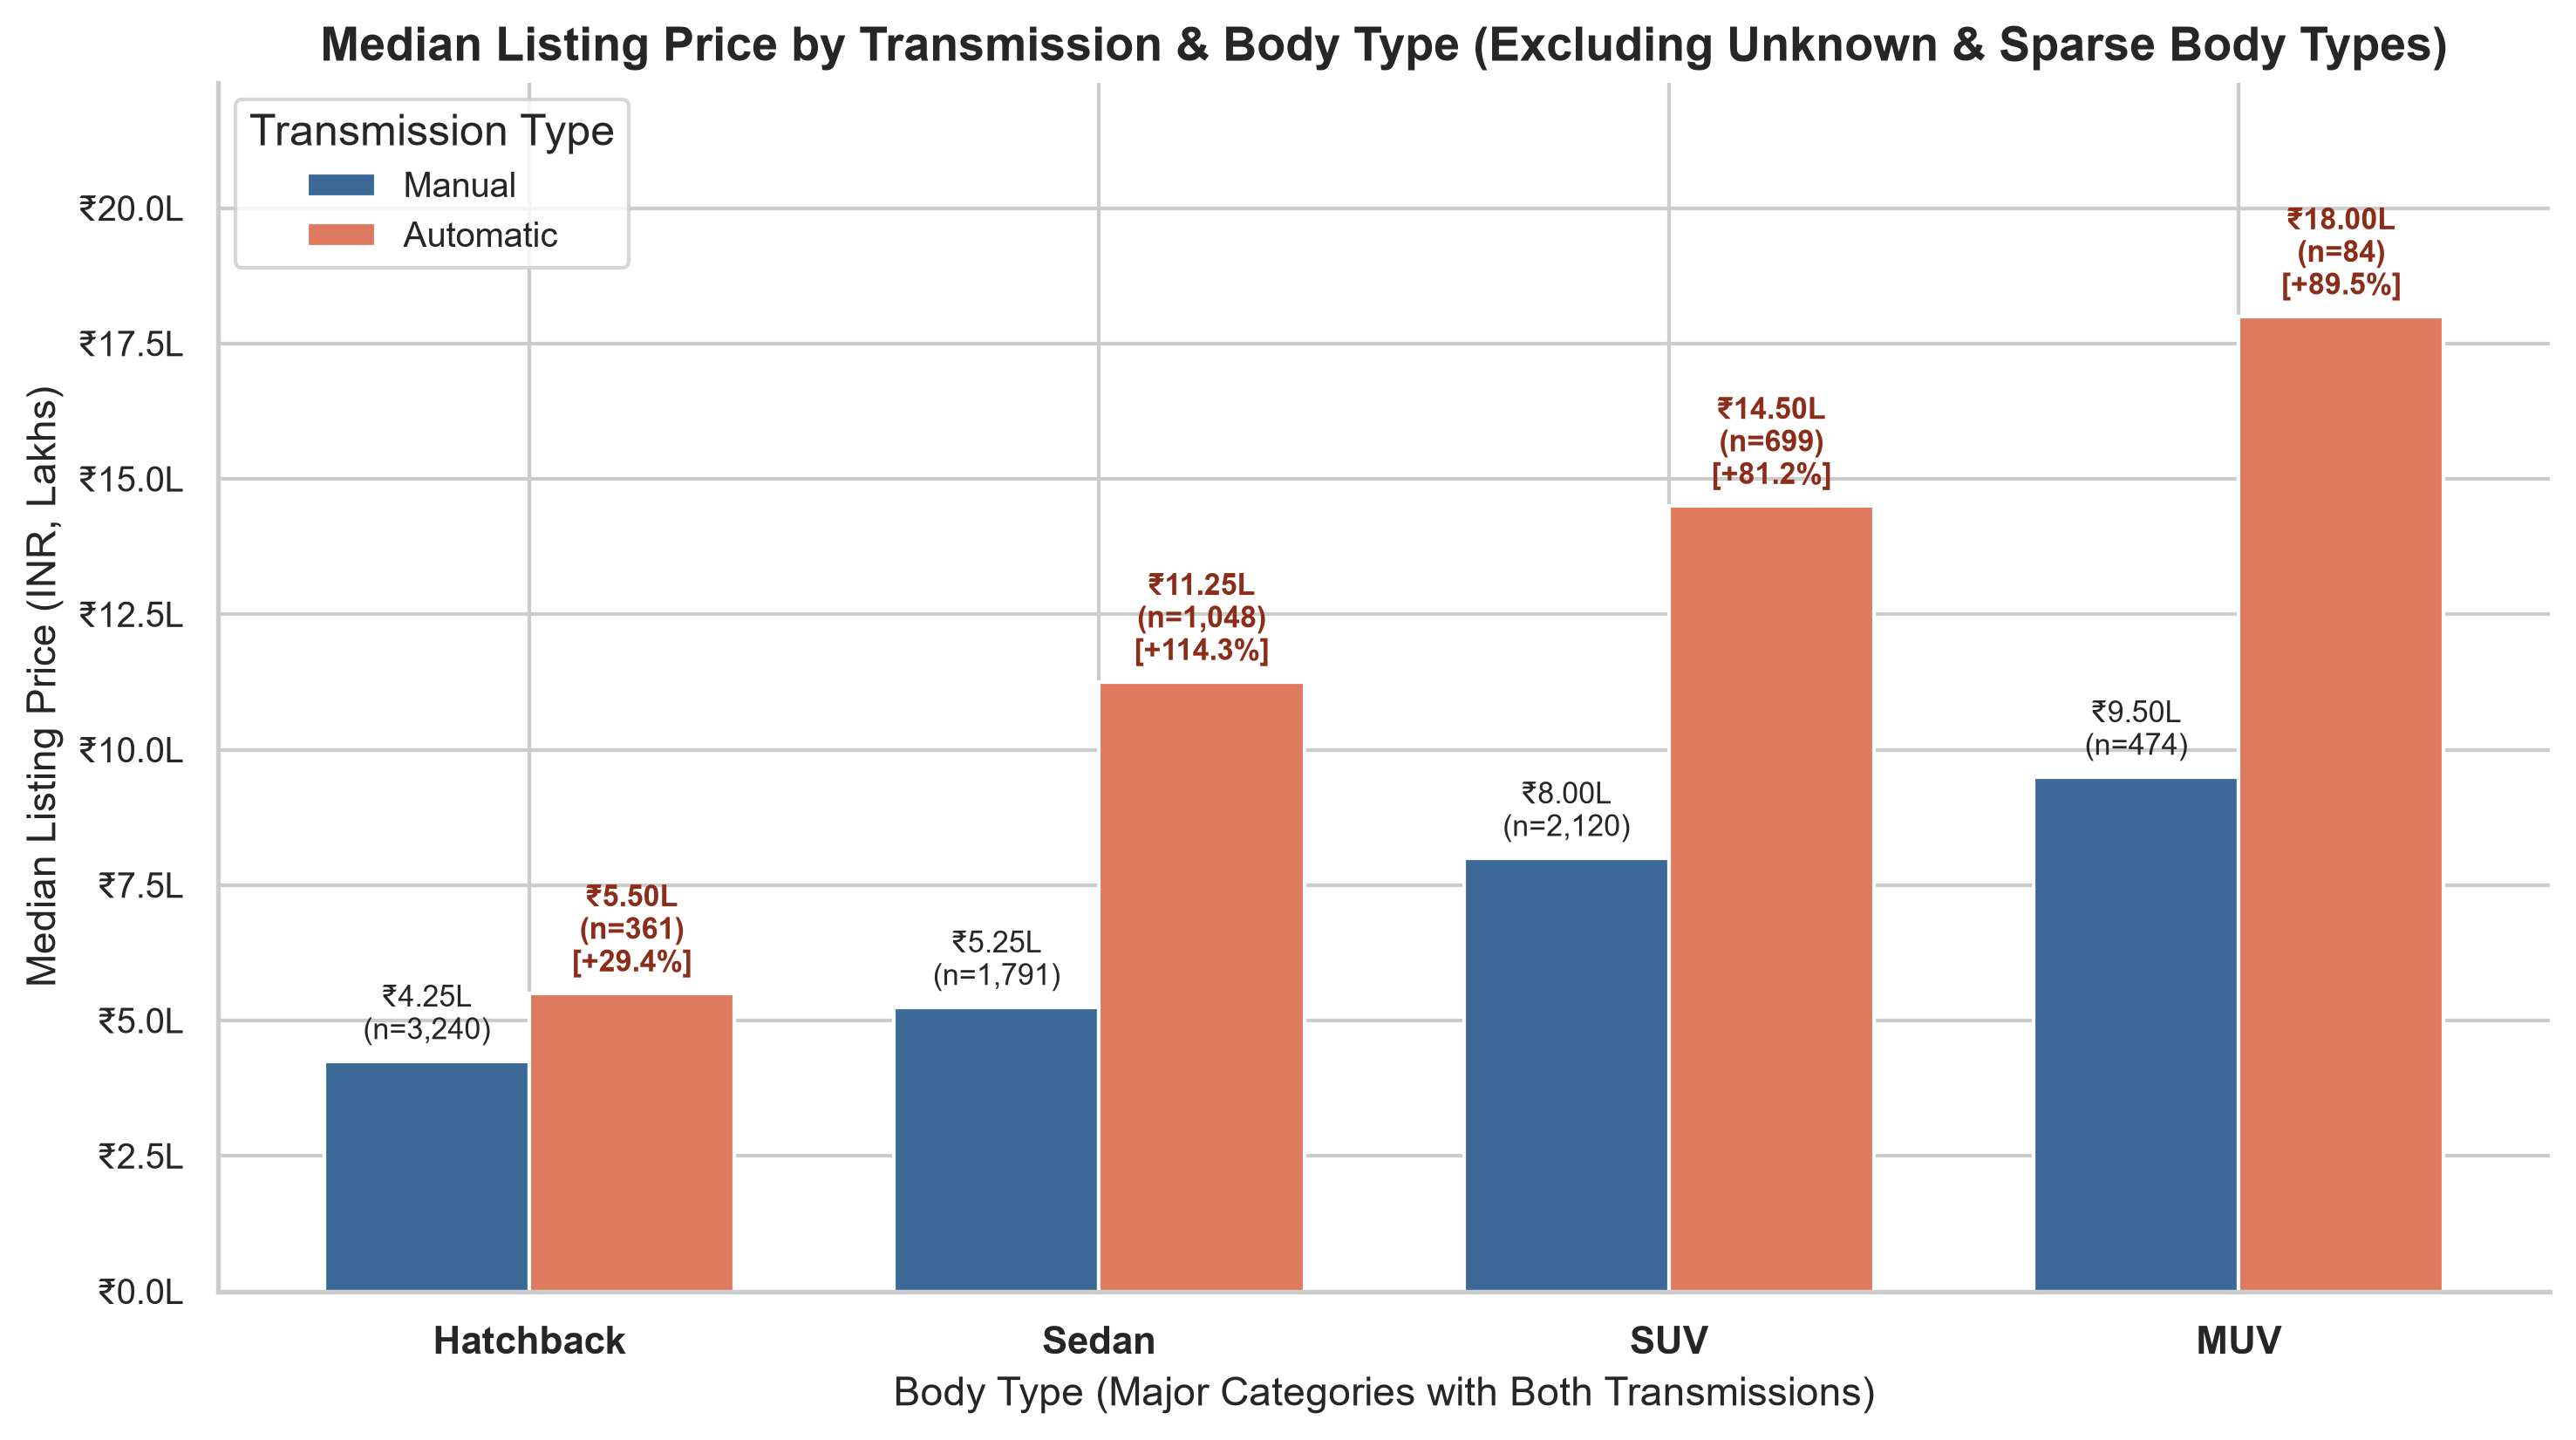

--- transmission_body_interaction.png ---


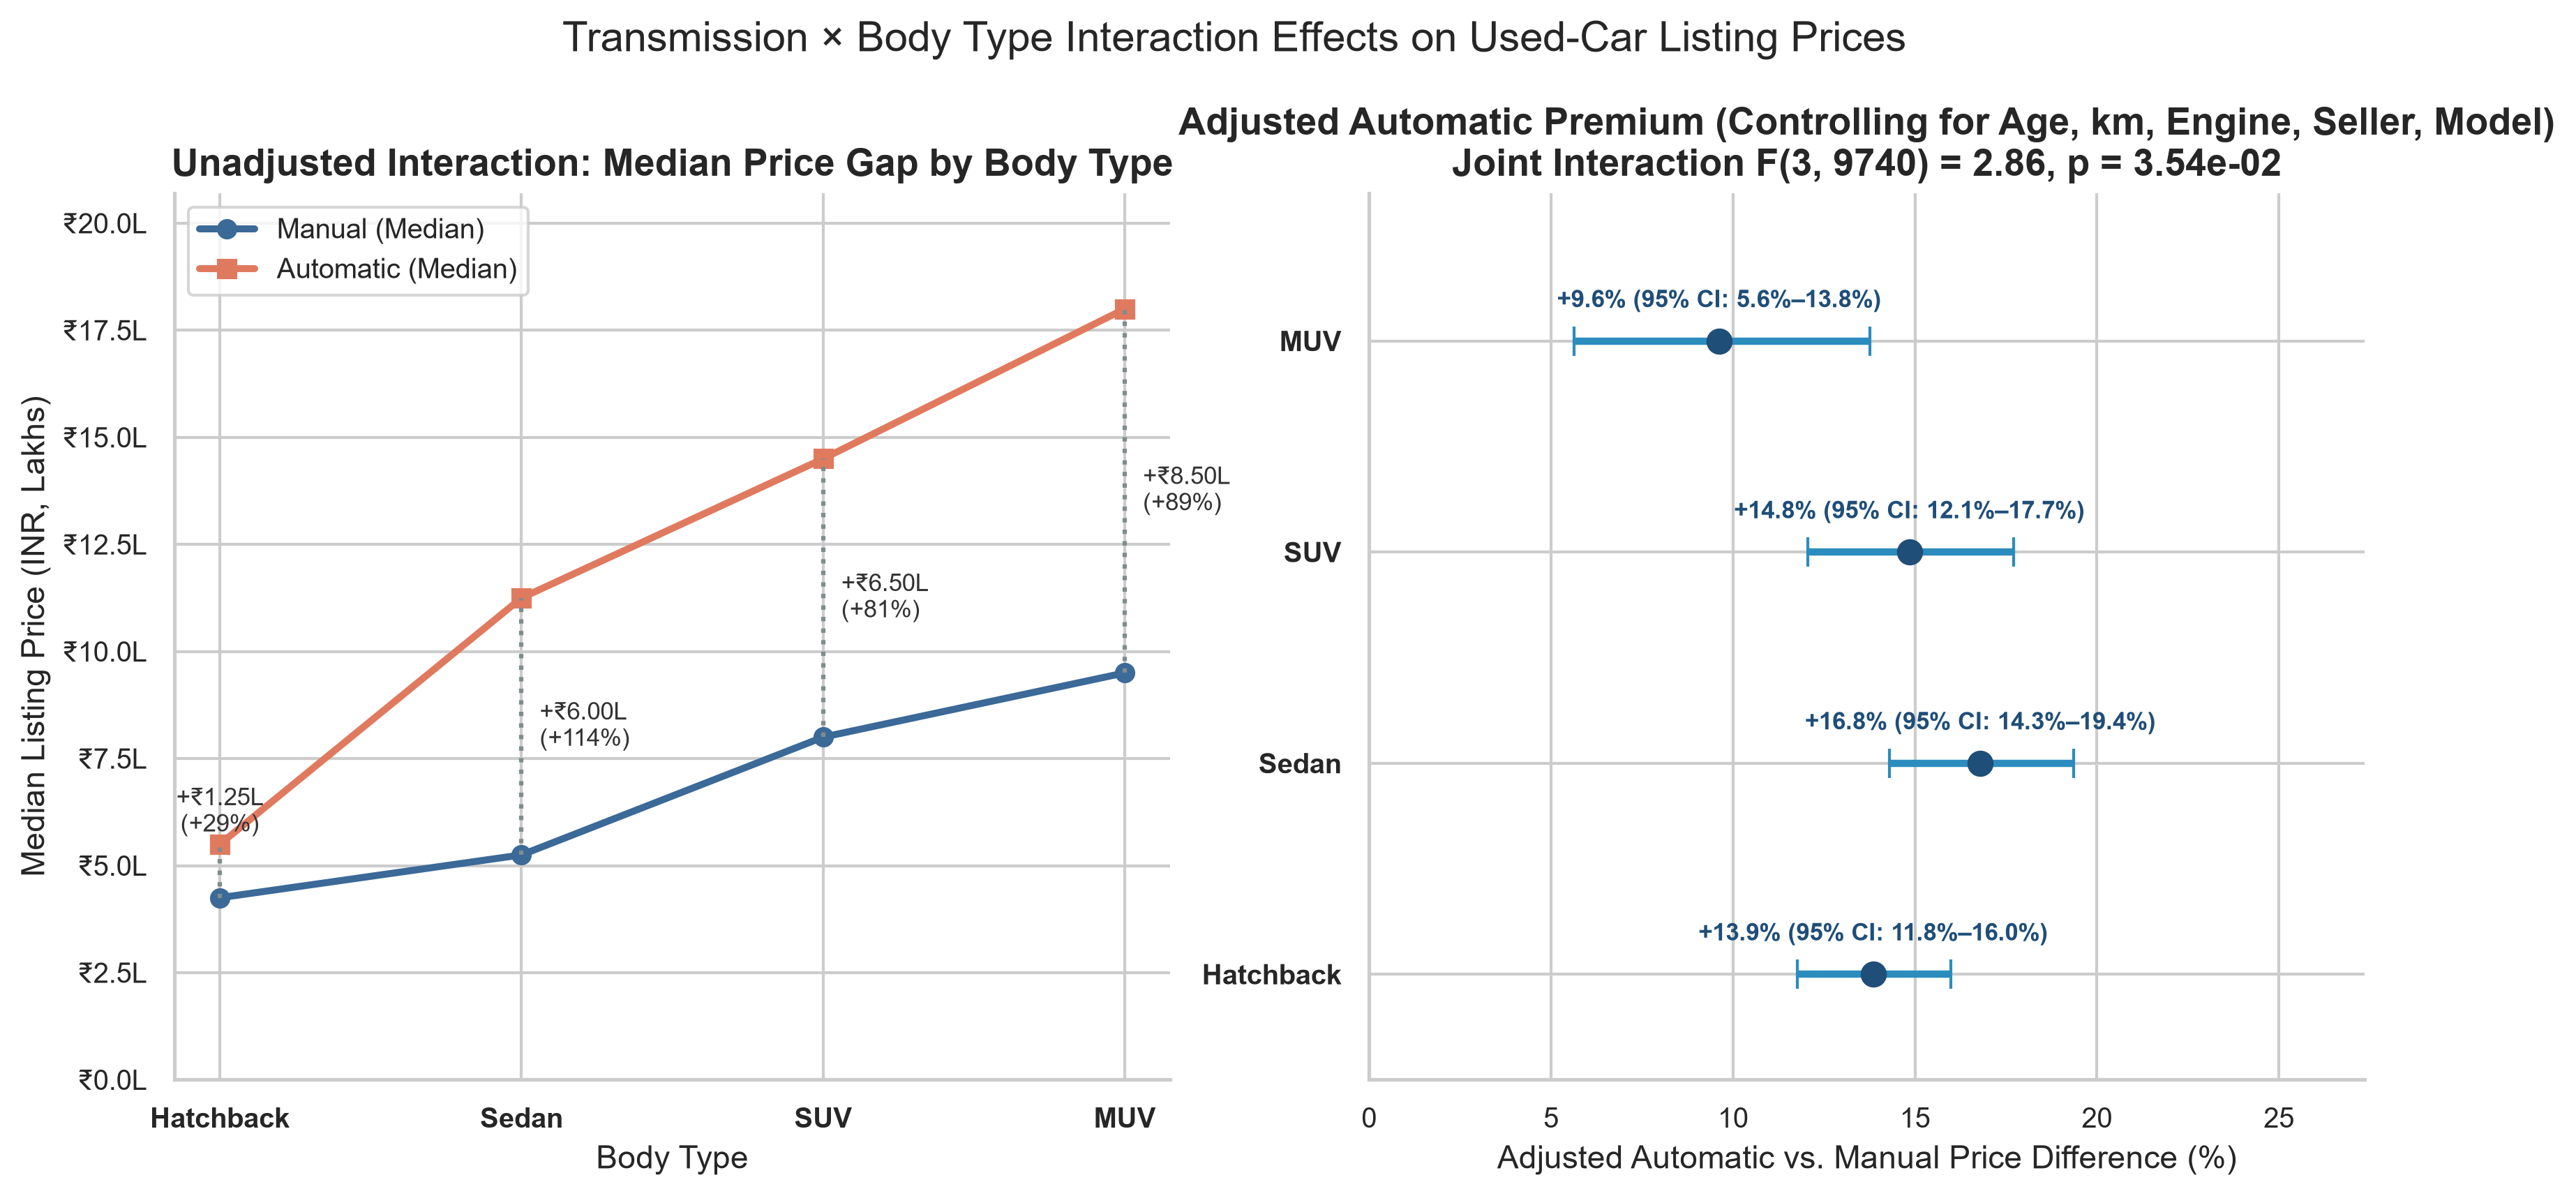

In [3]:
for fname in ["transmission_body_price_comparison.png", "transmission_body_interaction.png"]:
    print(f"--- {fname} ---")
    display(Image(filename=str(OUTPUT_FIG_DIR / fname), width=780))

### Business Conclusion
Do not price or value Automatic transmissions using raw segment medians (`+81%–114%`), which heavily overstate the true gearbox premium due to trim/model confounding. Within comparable vehicles (`same model, engine, age, mileage, seller`), Automatic listings carry a consistent **`+10%` to `+17%` price premium**, highest in Sedans (`+16.8%`) and SUVs (`+14.8%`) and more modest in MUVs (`+9.6%`).